In [ ]:
!pip install -Uqq fastbook
!pip install torch
import fastbook
fastbook.setup_book()
import torch

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 719.8/719.8 kB 7.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 542.1/542.1 kB 11.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 16.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.9/64.9 kB 10.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.1/194.1 kB 11.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.8/134.8 kB 11.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 17.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.3/21.3 MB 47.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.31.0, but you have requests 2.32.3 which is incompatible.


In [2]:
from fastai.imports import *
from fastai.torch_core import *
from fastai.learner import *

@patch
@delegates(subplots)
def plot_metrics(self: Recorder, nrows=None, ncols=None, figsize=None, **kwargs):
    metrics = np.stack(self.values)
    names = self.metric_names[1:-1]
    n = len(names) - 1
    if nrows is None and ncols is None:
        nrows = int(math.sqrt(n))
        ncols = int(np.ceil(n / nrows))
    elif nrows is None: nrows = int(np.ceil(n / ncols))
    elif ncols is None: ncols = int(np.ceil(n / nrows))
    figsize = figsize or (ncols * 6, nrows * 4)
    fig, axs = subplots(nrows, ncols, figsize=figsize, **kwargs)
    axs = [ax if i < n else ax.set_axis_off() for i, ax in enumerate(axs.flatten())][:n]
    for i, (name, ax) in enumerate(zip(names, [axs[0]] + axs)):
        ax.plot(metrics[:, i], color='#1f77b4' if i == 0 else '#ff7f0e', label='valid' if i > 0 else 'train')
        ax.set_title(name if i > 1 else 'losses')
        ax.legend(loc='best')
    plt.show()


In [3]:
from fastbook import *

In [4]:
from fastai.vision.all import *
path = Path('/content/gdrive/MyDrive/Kidney_stone_detection-Final Year/Dataset')

In [5]:
import torch

In [6]:
train_fnames = get_image_files(path/"Train")

In [7]:
augs = [RandomResizedCropGPU(size=112, min_scale=0.75), Rotate(), Zoom()]
dblock = DataBlock(blocks=(ImageBlock(cls=PILImage), CategoryBlock),
                   splitter=RandomSplitter(valid_pct=0.2, seed=23),
                   get_y=parent_label,
                   item_tfms=Resize(224, method="squish"),
                   batch_tfms=augs,
                   )

dls = dblock.dataloaders(train_fnames)


In [8]:
# print number of classes and length of train and valid datasets
dls.c, len(dls.train_ds), len(dls.valid_ds)

(3, 3642, 910)

In [9]:
dls.vocab

['Cyst', 'Kidney_stone', 'Normal']

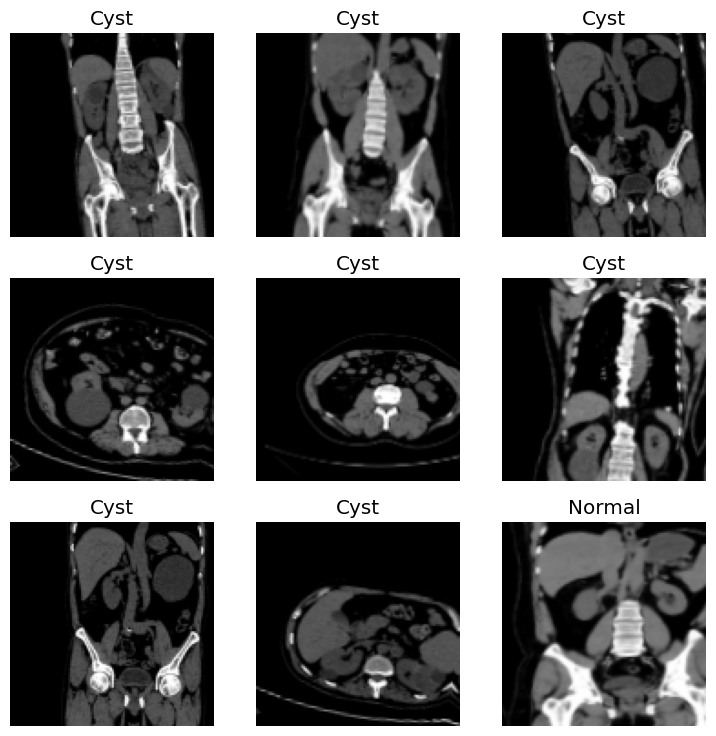

In [10]:
dls.show_batch()

In [11]:
model = nn.Sequential(create_body(xresnet50(), pretrained=False),create_head(nf=2048, n_out=3))
learn = Learner(dls, model, loss_func=CrossEntropyLossFlat(), metrics=accuracy)



In [ ]:
learn.fit_one_cycle(230,1e-2)
learn.recorder.plot_metrics()

In [ ]:
# Save model state_dict
torch.save(learn.model.state_dict(), path/'FinalTrained150-96.pth')


In [ ]:
learn.recorder.plot_loss(skip_start=0, with_valid=True)

In [12]:
#test_items = get_image_files(path/"Test")
all_files= get_image_files(path)

# Evaluating model performance using the unseen test set

---



In [13]:

augs = [RandomResizedCropGPU(size=112, min_scale=0.75), Rotate(), Zoom()]
dblock = DataBlock(blocks=(ImageBlock(cls=PILImage), CategoryBlock),
                   splitter=GrandparentSplitter(train_name='Train', valid_name='Test'),
                   get_y=parent_label,
                   item_tfms=Resize(224, method="squish"),
                   batch_tfms=augs,
                   )

dls_test = dblock.dataloaders(all_files)



In [14]:
print("Number of examples in testing:", len(dls_test.valid_ds))

Number of examples in testing: 956


In [15]:
model = nn.Sequential(create_body(xresnet50(), pretrained=True),create_head(nf=2048, n_out=3))

In [16]:
learn1 = learn1 = Learner(dls_test, model, loss_func=CrossEntropyLossFlat(), metrics=accuracy).load('/content/gdrive/MyDrive/Kidney_stone_detection-Final Year/Dataset/FinalTrained230-96_resnet50')
learn1.load('/content/gdrive/MyDrive/Kidney_stone_detection-Final Year/Dataset/FinalTrained230-96_resnet50')


/usr/local/lib/python3.10/dist-packages/fastai/learner.py:59: UserWarning: Saved file doesn't contain an optimizer state.
  elif with_opt: warn("Saved file doesn't contain an optimizer state.")


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [17]:
#Load the image which you want to test
img = "/content/gdrive/MyDrive/Kidney_stone_detection-Final Year/Dataset/Test/Cyst/Cyst- (1).jpg"
#Predict the image
probs = learn1.predict(img)
#print the prediction
print(probs)

('Cyst', tensor(0), tensor([1.0000e+00, 4.0511e-24, 2.8682e-22]))


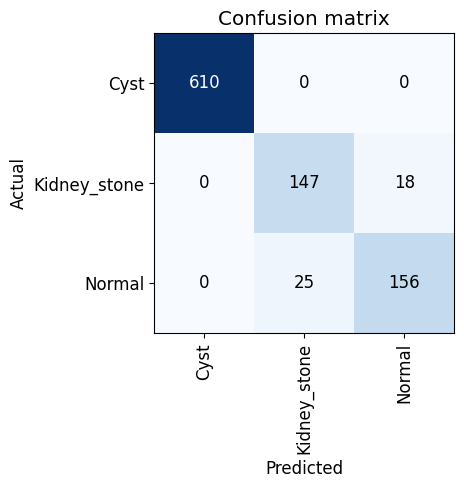

In [18]:
interp = ClassificationInterpretation.from_learner(learn1)
interp.plot_confusion_matrix()


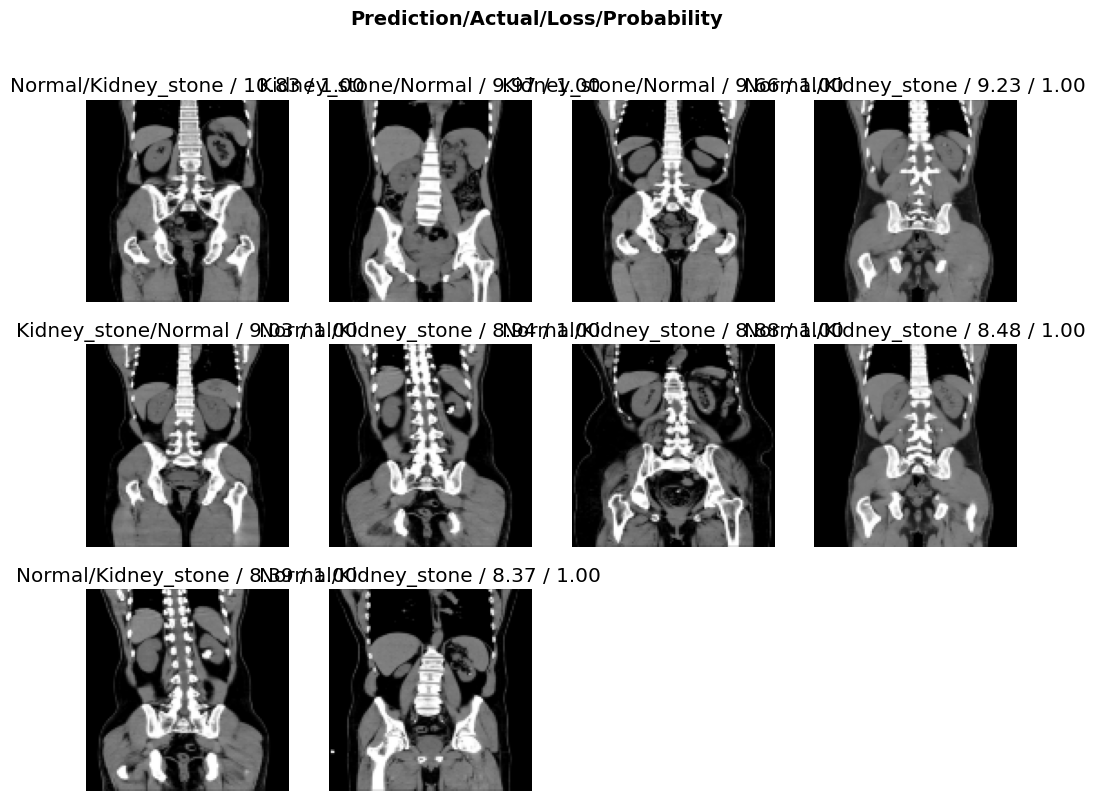

In [19]:
#Top 10 losses occured during validation of our test dataset
#for whole testing dataset
#interp.plot_top_losses(len(dls_test.valid_ds))
interp.plot_top_losses(10)


Top Losses: TensorBase([1.0825e+01, 9.9745e+00, 9.6576e+00, 9.2344e+00, 9.0270e+00, 8.9398e+00, 8.8780e+00, 8.4767e+00, 8.3946e+00, 8.3718e+00, 7.6032e+00, 7.4161e+00, 7.2946e+00, 6.8207e+00, 6.2976e+00,
            6.1605e+00, 5.8085e+00, 5.6953e+00, 5.6641e+00, 4.9818e+00, 3.7736e+00, 3.4992e+00, 3.2969e+00, 2.8349e+00, 2.8316e+00, 2.3727e+00, 2.2523e+00, 2.0807e+00, 2.0589e+00, 2.0063e+00,
            1.9971e+00, 1.9277e+00, 1.8931e+00, 1.8366e+00, 1.8067e+00, 1.4789e+00, 1.4106e+00, 1.3951e+00, 1.0408e+00, 1.0015e+00, 8.1684e-01, 7.6231e-01, 7.4400e-01, 6.1761e-01, 5.4381e-01,
            4.9858e-01, 4.5386e-01, 3.8301e-01, 3.5458e-01, 3.5390e-01, 3.4038e-01, 2.6024e-01, 2.4979e-01, 2.3370e-01, 2.1890e-01, 2.0449e-01, 1.9289e-01, 1.5699e-01, 1.3945e-01, 1.2400e-01,
            1.1112e-01, 1.0964e-01, 9.5495e-02, 8.2447e-02, 6.8335e-02, 6.2698e-02, 6.2477e-02, 6.0546e-02, 5.4912e-02, 4.9520e-02, 4.2833e-02, 3.9488e-02, 3.7997e-02, 3.0806e-02, 2.9401e-02,
            2.5612e-02, 2.05

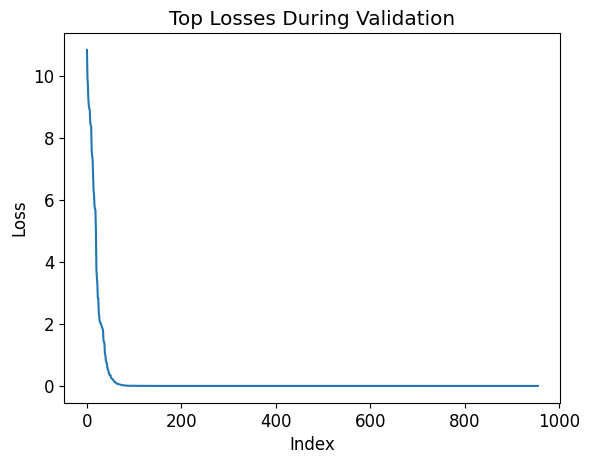

In [20]:
top_k_losses, top_k_idxs = interp.top_losses(k=len(dls_test.valid_ds), largest=True)  # Get top 5 highest losses
print("Top Losses:", top_k_losses)

#for whole dataset set value of k = len(dls_test.valid_ds)

import matplotlib.pyplot as plt

plt.plot(top_k_losses)  # Simple plot of top losses
plt.xlabel("Index")
plt.ylabel("Loss")
plt.title("Top Losses During Validation")
plt.show()



In [21]:
interp.print_classification_report()

              precision    recall  f1-score   support

        Cyst       1.00      1.00      1.00       610
Kidney_stone       0.85      0.89      0.87       165
      Normal       0.90      0.86      0.88       181

    accuracy                           0.96       956
   macro avg       0.92      0.92      0.92       956
weighted avg       0.96      0.96      0.96       956

